# Figure S12 — Cristiano vs Jiang: technical characteristics

- a: fragment-length distributions per cohort and clinical group (100–220 bp window);
- b: per-sample covariates by cohort and group (coverage, fragment count, mean fragment length, short/long ratio, mean fragment GC, sex inferred from the reads, ichorCNA tumour fraction);
- c: AUROC of each covariate alone within each cohort (participant bootstrap CI), next to the TSS model trained within that cohort (fully nested CV, pooled out-of-fold scores);
- the cohort characteristics table `tableS_cohorts.csv`.

Cohort: `FIG_COHORT` (default `no_deep`). Source data in `data/no_deep/`, written by `COHORT_VARIANT=no_deep python src/figures/export/export_figS12_cohorts.py`: `figS12_cohort_scalars.csv`, `figS12_fraglen_distributions.csv`, `tableS_cohorts.csv`; panel c also reads `fig3_predictions.csv`, `fig4a_predictions.csv` and `fig4gi_jiang_nested_oof.csv`. Run top to bottom from `src/figures/`.

In [1]:
import os, json

if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)


def data_path(name):
    p = os.path.join(_DATA, name)
    assert os.path.exists(p), f"{p} missing - run export/export_figS12_cohorts.py with COHORT_VARIANT={COHORT}"
    return p


def savefig(fig, name, **kw):
    import time
    for attempt in range(4):
        try:
            fig.savefig(os.path.join(_OUT, name), **kw); return
        except (FileNotFoundError, OSError):
            if attempt == 3: raise
            time.sleep(2 * (attempt + 1))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.metrics import roc_auc_score

sc = pd.read_csv(data_path("figS12_cohort_scalars.csv"))
dens = pd.read_csv(data_path("figS12_fraglen_distributions.csv"))
table = pd.read_csv(data_path("tableS_cohorts.csv"))
print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

LENGTHS = np.arange(100, 221)
GROUP_ORDER = [("Cristiano", "Healthy"), ("Cristiano", "BRCA+CRC"), ("Cristiano", "Other cancer"),
               ("Jiang", "Healthy"), ("Jiang", "Chronic hepatitis B"), ("Jiang", "HBV cirrhosis"), ("Jiang", "HCC")]
GROUP_COLORS = {("Cristiano", "Healthy"): "#2E8B57", ("Cristiano", "BRCA+CRC"): "#0173B2",
                ("Cristiano", "Other cancer"): "#7FB3D5",
                ("Jiang", "Healthy"): "#2E8B57", ("Jiang", "Chronic hepatitis B"): "#E69F00",
                ("Jiang", "HBV cirrhosis"): "#B15928", ("Jiang", "HCC"): "#CA3542"}
GROUP_LABELS = {"Healthy": "H", "BRCA+CRC": "B+C", "Other cancer": "Oth",
                "Chronic hepatitis B": "CHB", "HBV cirrhosis": "Cirr", "HCC": "HCC"}
GROUP_KEY = ("H = healthy, B+C = BRCA+CRC, Oth = other cancer types (Cristiano); "
             "H = healthy, CHB = chronic hepatitis B, Cirr = HBV cirrhosis, HCC (Jiang)")
sc["total_fragments_m"] = sc["total_fragments"] / 1e6
# continuous covariates of both cohorts (boxplots in b, AUROCs in c)
SCALARS = [("mean_coverage", "Mean coverage (x)", False),
           ("total_fragments_m", "Fragments per sample (millions)", False),
           ("fragment_length_mean", "Mean fragment length (bp)", False),
           ("short_long_ratio", "Short/long ratio (100–150 / 151–220)", False),
           ("mean_gc", "Mean fragment GC (%)", False)]
COV_LABELS = {c: l for c, l, _ in SCALARS} | {"sex_female_bam": "Female (sex from the reads)",
                                              "ichorcna_tf": "ichorCNA tumour fraction"}
UNI_COVS = [c for c, _, _ in SCALARS] + ["sex_female_bam", "ichorcna_tf"]

print(sc.groupby(["cohort", "group"]).size().to_string())
print("\n" + table.to_string(index=False, max_colwidth=70))

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)
cohort     group              
Cristiano  BRCA+CRC                80
           Healthy                164
           Other cancer           123
Jiang      Chronic hepatitis B     67
           HBV cirrhosis           36
           HCC                     90
           Healthy                 32

                                  characteristic                                                              cristiano                                                                  jiang                                                                 source
                                           Study                          Cristiano et al. 2019, Nature 570:385 (DELFI)                                      Jiang et al. 2015, PNAS 112:E1317                                                           publications
                                     Data source                    FinaleDB, hg38 fragment files (EG

## Panel a — fragment-length distributions

In [2]:
def panel_a(ax):
    cols = [str(l) for l in LENGTHS]
    for cohort, group in GROUP_ORDER:
        d = dens[(dens["cohort"] == cohort) & (dens["group"] == group)]
        if d.empty:
            continue
        mean = d[cols].mean(axis=0).to_numpy() * 100
        ax.plot(LENGTHS, mean, color=GROUP_COLORS[(cohort, group)],
                linestyle="-" if cohort == "Cristiano" else "--",
                linewidth=1.3 if group == "Other cancer" else 2,
                label=f"{cohort} {group} (n = {len(d)})")
    ax.set_xlabel("Fragment length (bp)", fontsize=13)
    ax.set_ylabel("Fragments (% of 100–220 bp window)", fontsize=13)
    ax.set_xlim(100, 220)
    ax.legend(fontsize=9, frameon=True, framealpha=0.9, edgecolor="#cccccc", title="solid = Cristiano, dashed = Jiang",
              title_fontsize=9)
    ax.tick_params(labelsize=11)

## Panel b — technical covariates by cohort and group

In [3]:
def _cohort_divider(ax, x=2.5):
    ax.axvline(x, color="black", linewidth=1, alpha=0.5)
    ax.text(0.03, 0.97, "Cristiano", transform=ax.transAxes, ha="left", va="top", fontsize=8.5, color="dimgray")
    ax.text(0.97, 0.97, "Jiang", transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color="dimgray")


def _boxes(ax, col, groups):
    data = [sc.loc[(sc["cohort"] == c) & (sc["group"] == g), col].dropna().to_numpy() for c, g in groups]
    colors = [GROUP_COLORS[k] for k in groups]
    pos = np.arange(len(data))
    bp = ax.boxplot([d if len(d) else [np.nan] for d in data], positions=pos, widths=0.6,
                    patch_artist=True, showfliers=False, medianprops={"color": "black", "linewidth": 1.6})
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.45)
    rng = np.random.default_rng(0)
    for xi, (v, c) in enumerate(zip(data, colors)):
        ax.scatter(xi + rng.uniform(-0.2, 0.2, len(v)), v, s=6, color=c, alpha=0.6, zorder=3, linewidths=0)
    ax.set_xticks(pos)
    ax.set_xticklabels([GROUP_LABELS[g] for _, g in groups], fontsize=8, rotation=60, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="y", labelsize=9)


def panel_b(axes):
    """Five continuous covariates, then sex (% female per group), then the ichorCNA
    tumour fraction (log scale; both cohorts)."""
    for ax, (col, label, log) in zip(axes, SCALARS):
        _boxes(ax, col, GROUP_ORDER)
        ax.set_title(label, fontsize=10.5)
        if log:
            ax.set_yscale("log")
        _cohort_divider(ax)
    ax = axes[len(SCALARS)]
    pct = [100 * sc.loc[(sc["cohort"] == c) & (sc["group"] == g), "sex_female_bam"].mean() for c, g in GROUP_ORDER]
    ax.bar(np.arange(len(GROUP_ORDER)), pct, color=[GROUP_COLORS[k] for k in GROUP_ORDER], alpha=0.6,
           edgecolor="black", linewidth=0.5)
    for xi, p in enumerate(pct):
        ax.text(xi, p + 1.5, f"{p:.0f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(GROUP_ORDER)))
    ax.set_xticklabels([GROUP_LABELS[g] for _, g in GROUP_ORDER], fontsize=8, rotation=60, ha="right", rotation_mode="anchor")
    ax.set_ylim(0, 112)
    ax.set_title("Female (%), sex from the reads", fontsize=10.5)
    ax.tick_params(axis="y", labelsize=9)
    _cohort_divider(ax)
    ax = axes[len(SCALARS) + 1]
    _boxes(ax, "ichorcna_tf", GROUP_ORDER)
    ax.set_yscale("log")
    ax.axhline(0.03, color="0.4", linestyle=":", linewidth=1)
    ax.set_title("ichorCNA tumour fraction (log)", fontsize=10.5)
    _cohort_divider(ax)
    axes[0].set_xlabel(GROUP_KEY, fontsize=8.5, loc="left", color="dimgray", labelpad=6)


# healthy-vs-healthy comparison of every covariate (the cohort effect, no disease)
rows = []
for col in UNI_COVS:
    a = sc.loc[(sc["cohort"] == "Cristiano") & (sc["group"] == "Healthy"), col].dropna()
    b = sc.loc[(sc["cohort"] == "Jiang") & (sc["group"] == "Healthy"), col].dropna()
    rows.append({"covariate": col, "cristiano_healthy_median": a.median(), "jiang_healthy_median": b.median(),
                 "cristiano_healthy_mean": a.mean(), "jiang_healthy_mean": b.mean(),
                 "mwu_p": mannwhitneyu(a, b).pvalue,
                 "auroc_healthy_vs_healthy": roc_auc_score([0] * len(a) + [1] * len(b), np.r_[a, b])})
healthy_vs_healthy = pd.DataFrame(rows)
print("Healthy Cristiano vs healthy Jiang, per covariate:")
print(healthy_vs_healthy.round(4).to_string(index=False))

Healthy Cristiano vs healthy Jiang, per covariate:
           covariate  cristiano_healthy_median  jiang_healthy_median  cristiano_healthy_mean  jiang_healthy_mean  mwu_p  auroc_healthy_vs_healthy
       mean_coverage                    2.3218                2.2432                  2.4246              2.2256 0.0844                    0.4034
   total_fragments_m                   37.8087               36.7938                 39.5374             36.4241 0.0988                    0.4076
fragment_length_mean                  165.7523              169.2238                165.9520            169.1131 0.0000                    0.9282
    short_long_ratio                    0.2409                0.1453                  0.2415              0.1477 0.0000                    0.0192
             mean_gc                   38.3131               41.4821                 38.2883             41.4119 0.0000                    0.9950
      sex_female_bam                    1.0000                0.0000     

## Panel c — do simple covariates carry the disease signal within each cohort?

AUROC of each covariate alone (higher value = cancer; below 0.5 = opposite direction), participant bootstrap 95% CI, without training-fold orientation.

In [4]:
def boot_auc(y, s, n_boot=2000, seed=42):
    y, s = np.asarray(y, dtype=int), np.asarray(s, dtype=float)
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    boots = [roc_auc_score(y[i], s[i]) for i in
             (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n_boot))]
    return roc_auc_score(y, s), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


TASKS = {
    "Cristiano: BRCA+CRC vs healthy": sc[(sc["cohort"] == "Cristiano") & sc["group"].isin(["Healthy", "BRCA+CRC"])],
    "Cristiano: all cancers vs healthy": sc[sc["cohort"] == "Cristiano"],
    "Jiang: HCC vs all non-HCC": sc[sc["cohort"] == "Jiang"],
    "Jiang: HCC vs healthy": sc[(sc["cohort"] == "Jiang") & sc["group"].isin(["Healthy", "HCC"])],
}
TASK_COLORS = {"Cristiano: BRCA+CRC vs healthy": "#0173B2", "Cristiano: all cancers vs healthy": "#7FB3D5",
               "Jiang: HCC vs all non-HCC": "#CA3542",
               "Jiang: HCC vs healthy": "#E69F00"}
uni_rows = []
for task, df in TASKS.items():
    for col in UNI_COVS:
        label = COV_LABELS[col]
        d = df[[col, "is_cancer"]].dropna()
        if d["is_cancer"].nunique() < 2:
            continue
        a, lo, hi = boot_auc(d["is_cancer"], d[col])
        uni_rows.append({"task": task, "covariate": col, "label": label, "auroc": a, "ci_low": lo, "ci_high": hi,
                         "n_cancer": int(d["is_cancer"].sum()), "n_control": int((d["is_cancer"] == 0).sum())})
# reference: the TSS model trained within each cohort (fully nested CV), pooled out-of-fold scores
TSS_REF = {
    "Cristiano: BRCA+CRC vs healthy": pd.read_csv(data_path("fig3_predictions.csv")).query("method == 'data_driven'"),
    "Cristiano: all cancers vs healthy": pd.read_csv(data_path("fig4a_predictions.csv")).query("method == 'data_driven'"),
    "Jiang: HCC vs all non-HCC": pd.read_csv(data_path("fig4gi_jiang_nested_oof.csv")).query("task == 'hcc_vs_nonhcc'"),
    "Jiang: HCC vs healthy": pd.read_csv(data_path("fig4gi_jiang_nested_oof.csv")).query("task == 'hcc_vs_healthy'"),
}
COV_LABELS["tss_model_nested"] = "TSS model trained within the cohort"
for task, d in TSS_REF.items():
    a, lo, hi = boot_auc(d["y_true"], d["score"])
    fold = d["fold"] if "fold" in d else d["outer_fold"]
    fm = np.mean([roc_auc_score(g["y_true"], g["score"]) for _, g in d.groupby(fold)])
    uni_rows.append({"task": task, "covariate": "tss_model_nested", "label": COV_LABELS["tss_model_nested"],
                     "auroc": a, "ci_low": lo, "ci_high": hi, "fold_mean_auroc": fm,
                     "n_cancer": int(d["y_true"].sum()), "n_control": int((d["y_true"] == 0).sum())})
uni = pd.DataFrame(uni_rows)


def panel_c(ax):
    covs = [c for c in UNI_COVS + ["tss_model_nested"] if c in set(uni["covariate"])]
    x = np.arange(len(covs))
    tasks = list(TASKS)
    w = 0.8 / len(tasks)
    for i, task in enumerate(tasks):
        r = uni[uni["task"] == task].set_index("covariate").reindex(covs)
        xs = x + (i - (len(tasks) - 1) / 2) * w
        ax.errorbar(xs, r["auroc"], yerr=[r["auroc"] - r["ci_low"], r["ci_high"] - r["auroc"]], fmt="o",
                    color=TASK_COLORS[task], ecolor=TASK_COLORS[task], markersize=6, capsize=3, elinewidth=1.2,
                    markeredgecolor="black", markeredgewidth=0.4, linestyle="none", label=task)
    ax.axhline(0.5, color="black", linestyle="--", linewidth=1, alpha=0.4)
    ax.axvline(len(covs) - 1.5, color="0.5", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels([COV_LABELS[c].split(" (")[0] for c in covs], fontsize=9, rotation=20, ha="right")
    ax.set_ylabel("AUROC within each cohort\n(bootstrap 95% CI)", fontsize=11)
    ax.set_ylim(0.1, 1.02)
    ax.legend(fontsize=9, frameon=True, framealpha=0.9, edgecolor="#cccccc", loc="upper left")
    ax.tick_params(labelsize=10)


print(uni.round(3).to_string(index=False))

                             task            covariate                                label  auroc  ci_low  ci_high  n_cancer  n_control  fold_mean_auroc
   Cristiano: BRCA+CRC vs healthy        mean_coverage                    Mean coverage (x)  0.586   0.507    0.666        80        164              NaN
   Cristiano: BRCA+CRC vs healthy    total_fragments_m      Fragments per sample (millions)  0.591   0.512    0.672        80        164              NaN
   Cristiano: BRCA+CRC vs healthy fragment_length_mean            Mean fragment length (bp)  0.258   0.183    0.337        80        164              NaN
   Cristiano: BRCA+CRC vs healthy     short_long_ratio Short/long ratio (100–150 / 151–220)  0.701   0.617    0.780        80        164              NaN
   Cristiano: BRCA+CRC vs healthy              mean_gc                 Mean fragment GC (%)  0.612   0.530    0.697        80        164              NaN
   Cristiano: BRCA+CRC vs healthy       sex_female_bam          Female (sex 

## Assemble Figure S12

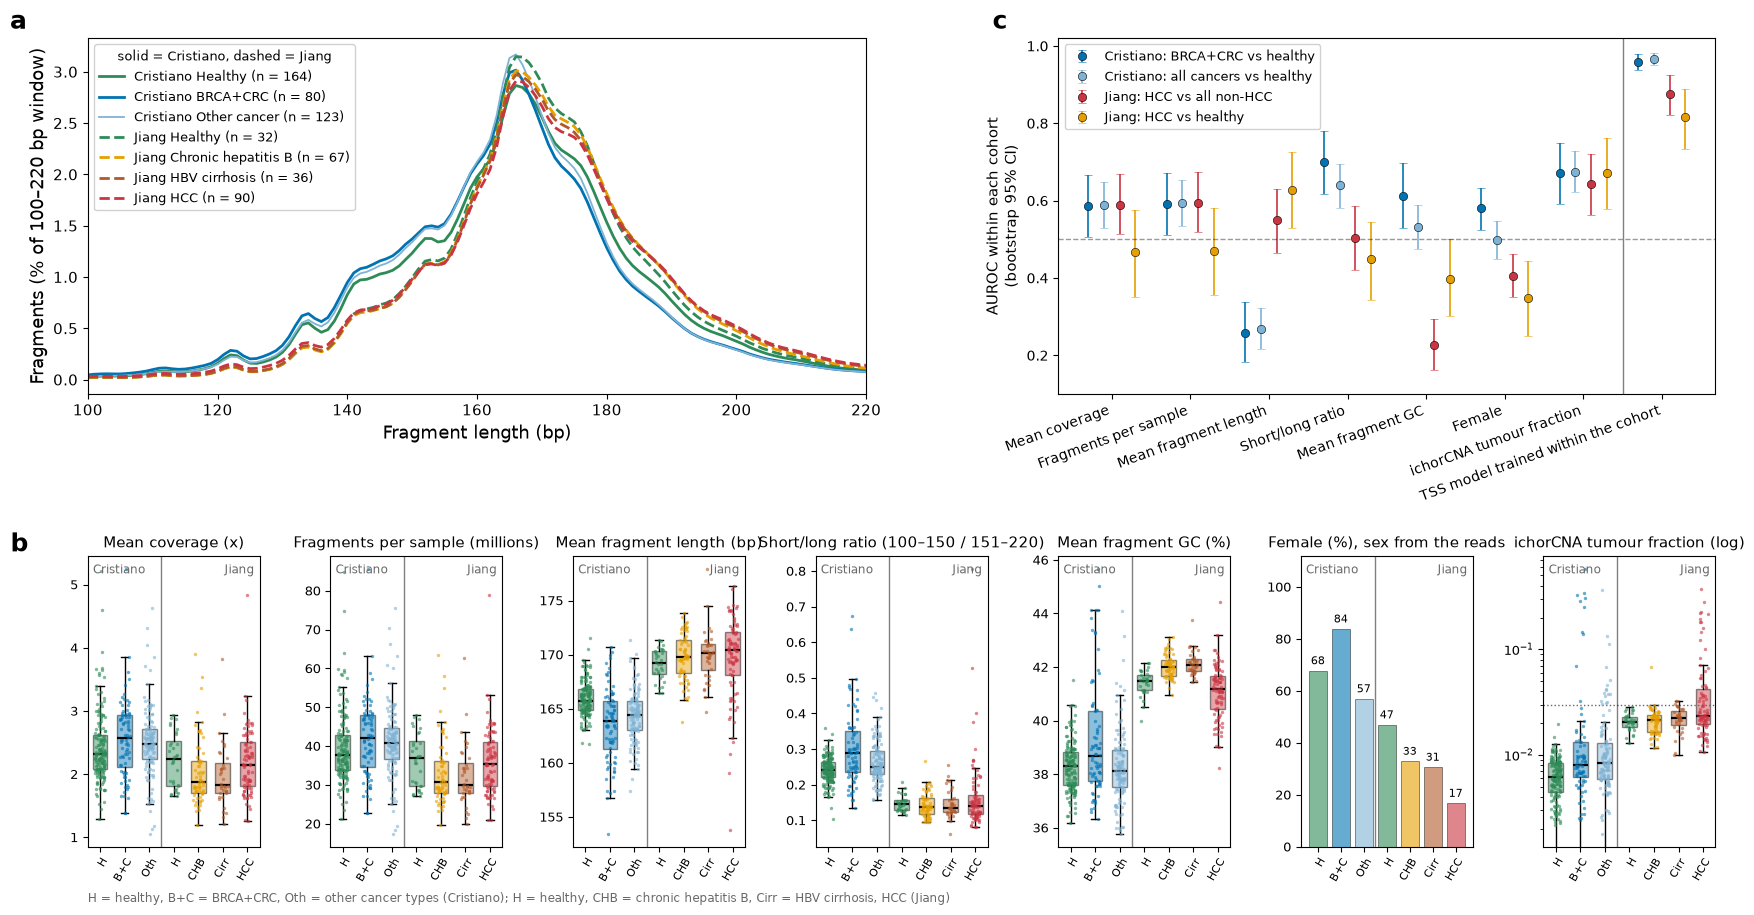

In [5]:
fig = plt.figure(figsize=(21, 10.5))
gs = fig.add_gridspec(2, 14, height_ratios=[1.1, 0.9], hspace=0.5, wspace=1.4)
ax_a = fig.add_subplot(gs[0, :7])
ax_c = fig.add_subplot(gs[0, 8:])
axes_b = [fig.add_subplot(gs[1, 2 * i:2 * i + 2]) for i in range(7)]
panel_a(ax_a)
panel_b(axes_b)
panel_c(ax_c)
for ax, letter in [(ax_a, "a"), (axes_b[0], "b"), (ax_c, "c")]:
    ax.text(-0.1 if ax is not axes_b[0] else -0.45, 1.08, letter, transform=ax.transAxes,
            fontsize=18, fontweight="bold", va="top")
savefig(fig, "figS12.png", dpi=300, bbox_inches="tight")
savefig(fig, "figS12.pdf", bbox_inches="tight")
plt.show()

## Summary numbers

In [6]:
GO = pd.MultiIndex.from_tuples(GROUP_ORDER)
print("Per-group medians:")
print(sc.groupby(["cohort", "group"])[[c for c, _, _ in SCALARS] + ["ichorcna_tf"]].median().reindex(GO).round(4).to_string())
print("\nFraction female per group:")
print(sc.groupby(["cohort", "group"])["sex_female_bam"].mean().reindex(GO).round(3).to_string())
print("\nHealthy Cristiano vs healthy Jiang (cohort effect without disease):")
print(healthy_vs_healthy.round(4).to_string(index=False))
print("\nCovariates alone within each cohort (panel c):")
print(uni.round(3).to_string(index=False))

Per-group medians:
                               mean_coverage  total_fragments_m  fragment_length_mean  short_long_ratio  mean_gc  ichorcna_tf
Cristiano Healthy                     2.3218            37.8087              165.7523            0.2409  38.3131       0.0062
          BRCA+CRC                    2.5693            42.0935              163.8411            0.2897  38.6750       0.0081
          Other cancer                2.4836            40.6763              164.4027            0.2510  38.1058       0.0083
Jiang     Healthy                     2.2432            36.7938              169.2238            0.1453  41.4821       0.0206
          Chronic hepatitis B         1.8763            30.6774              169.7917            0.1384  42.0014       0.0215
          HBV cirrhosis               1.8304            29.9698              170.1084            0.1353  42.0701       0.0225
          HCC                         2.1520            35.2543              170.3897            0.